# Đánh giá mô hình LSTM


In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd().resolve()
if not (ROOT / "ems").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "ems").is_dir():
    raise RuntimeError("Run from project root or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

from ems.models.lstm.config     import *
from ems.models.lstm.preprocess import build_dataloaders
from ems.models.lstm.model      import build_model
from ems.models.lstm.train      import train, load_checkpoint
from ems.models.lstm.evaluate   import (predict, compute_metrics, print_metrics,
                             plot_loss_curve, plot_predictions,
                             plot_comparison, naive_baseline, evaluate_all)



## Naive Baseline
Dùng giá trị giờ trước (lag-1) làm dự báo

In [2]:
import pandas as pd
from ems.models.lstm.config import DATA_DIR, TARGET_COL

y_test_raw = pd.read_csv(os.path.join(DATA_DIR, "y_test.csv"))[TARGET_COL].values
baseline_metrics = naive_baseline(y_test_raw)
print_metrics(baseline_metrics, run_name="Naive Lag-1 Baseline")



──────────────────────────────────────────────────
  Evaluation Metrics — Naive Lag-1 Baseline
──────────────────────────────────────────────────
  MAE         : 4.2040
  RMSE        : 5.3417
  MAPE (%)    : 45.1775
  R²          : -0.1544
──────────────────────────────────────────────────



## Vanilla LSTM với seq_len=24 (1 ngày)

In [3]:
SEQ_LEN = 24
RUN_NAME = f"vanilla_seq{SEQ_LEN}"

train_dl_24, val_dl_24, test_dl_24, feat_scaler, tgt_scaler = build_dataloaders(
    seq_len=SEQ_LEN, batch_size=BATCH_SIZE, verbose=True
)


[Preprocess] seq_len=24
  Train:  X=(52416, 24, 34), y=(52416, 1)
  Val:    X=(8736, 24, 34), y=(8736, 1)
  Test:   X=(6772, 24, 34), y=(6772, 1)


In [4]:
model_24 = build_model(
    name="vanilla",
    n_features=N_FEATURES,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
)
print(model_24)
total_params = sum(p.numel() for p in model_24.parameters() if p.requires_grad)
print(f"\nTotal trainable params: {total_params:,}")


VanillaLSTM(
  (lstm): LSTM(34, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total trainable params: 224,385


In [5]:
history_24 = train(
    model=model_24,
    train_dl=train_dl_24,
    val_dl=val_dl_24,
    run_name=RUN_NAME,
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
)



  Training: vanilla_seq24  |  device=cpu


c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  Epoch    1/30 | train=0.00988 | val=0.00805 | lr=1.00e-03 | 22s
  Epoch    5/30 | train=0.00782 | val=0.00801 | lr=1.00e-03 | 110s
  Epoch   10/30 | train=0.00775 | val=0.00796 | lr=5.00e-04 | 284s
  Epoch   15/30 | train=0.00767 | val=0.00778 | lr=5.00e-04 | 483s
  Epoch   20/30 | train=0.00765 | val=0.00779 | lr=5.00e-04 | 588s
  Epoch   25/30 | train=0.00764 | val=0.00778 | lr=2.50e-04 | 843s
  Epoch   30/30 | train=0.00757 | val=0.00772 | lr=2.50e-04 | 1125s
  ✅ Best model saved → f:\ems-forecast\checkpoints\vanilla_seq24_best.pth



──────────────────────────────────────────────────
  Evaluation Metrics — vanilla_seq24
──────────────────────────────────────────────────
  MAE         : 2.9820
  RMSE        : 3.8387
  MAPE (%)    : 33.2954
  R²          : 0.4041
──────────────────────────────────────────────────

  [Plot] Saved → f:\ems-forecast\outputs\loss_vanilla_seq24.png
  [Plot] Saved → f:\ems-forecast\outputs\preds_vanilla_seq24.png


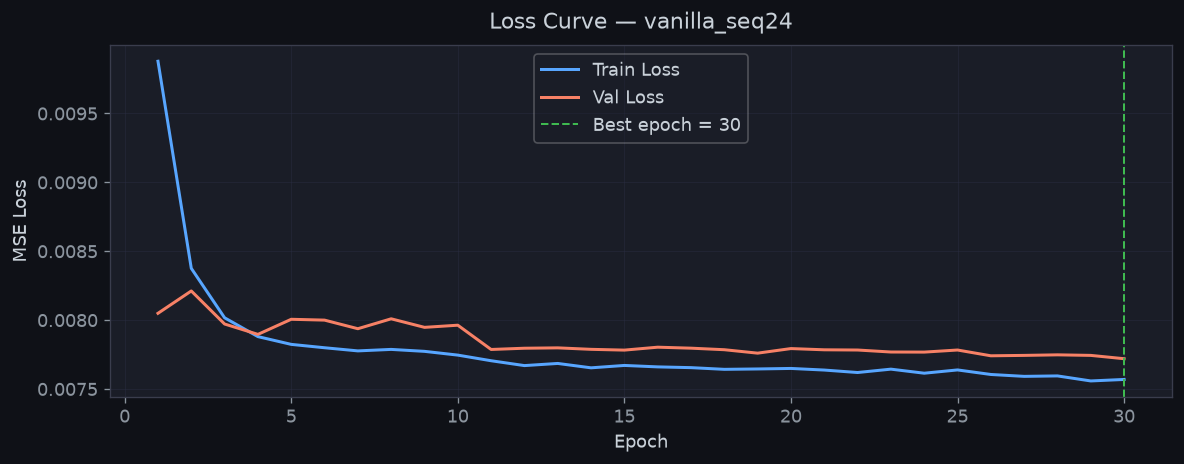

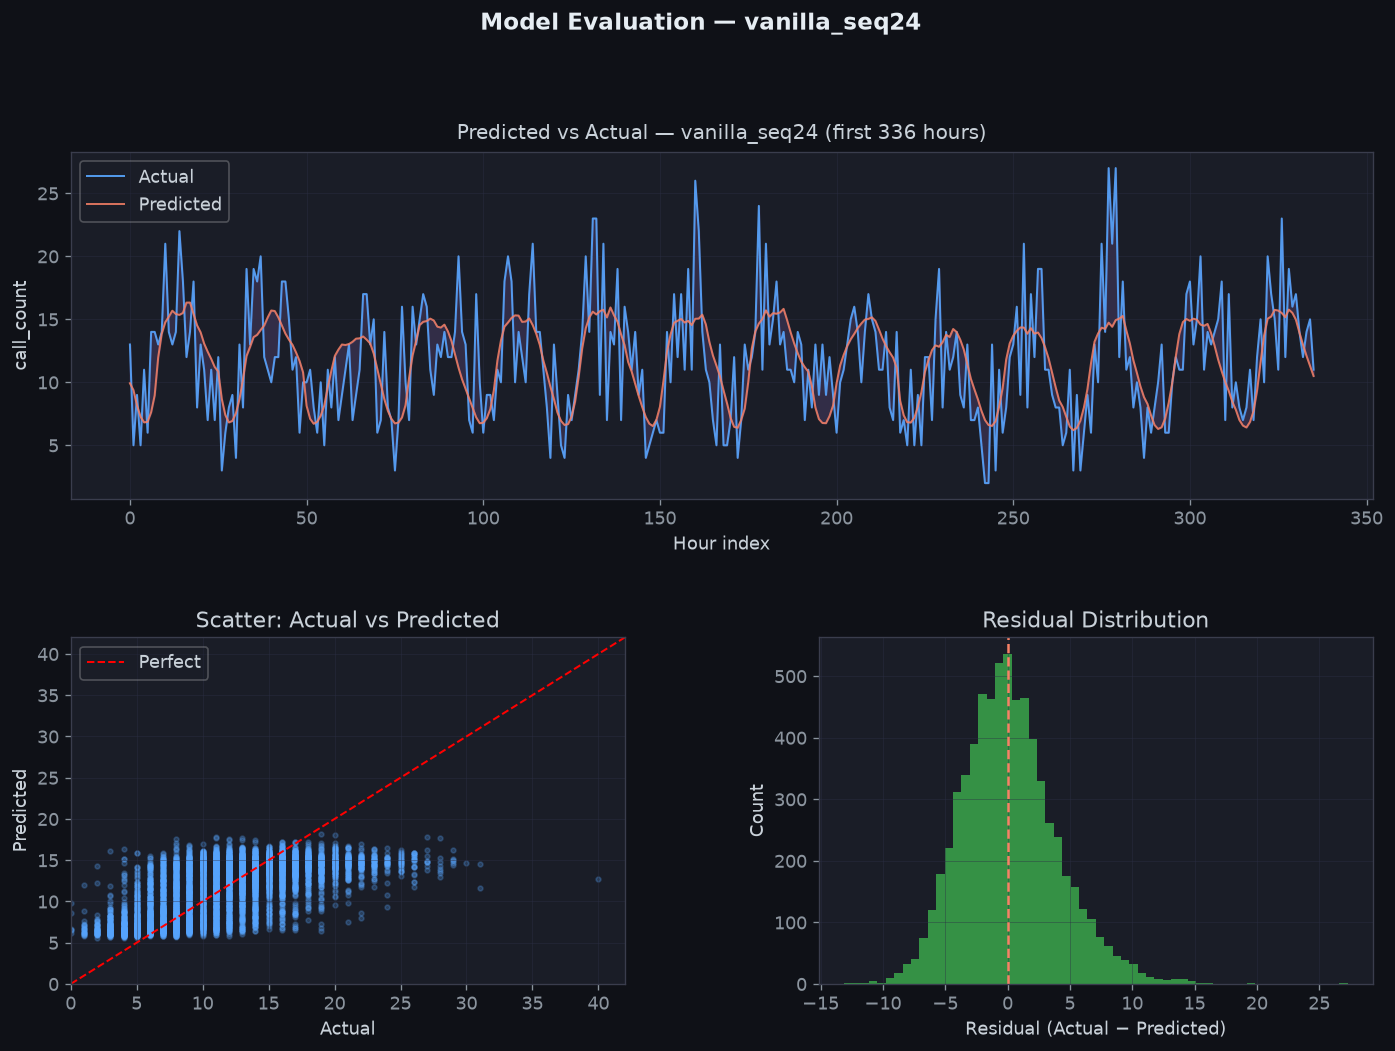

In [6]:
y_true_24, y_pred_24, metrics_24 = evaluate_all(
    model=model_24,
    test_dl=test_dl_24,
    tgt_scaler=tgt_scaler,
    run_name=RUN_NAME,
    history=history_24,
)
plt.show()
